In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import equilibrator_api
from equilibrator_api import ComponentContribution, Q_, ureg, Reaction
import equilibrator_pathway
from equilibrator_pathway import ThermodynamicModel

import warnings
warnings.filterwarnings('ignore')

ureg.formatter.default_format = ".2f~P"
plt.rc('axes', axisbelow=True)
ureg.setup_matplotlib(True)

comp_contrib = ComponentContribution()

pH 7.5, ionic strength 250 mM, pMg 3, 25 degC

In [3]:
comp_contrib.p_h = Q_(7.5)
comp_contrib.ionic_strength = Q_('250 mM')
comp_contrib.p_mg = Q_(3)

## First check reaction thermodynamics
* FDH + FPR: formate + 2 ferredoxin(ox) <=> CO2 + 2 ferredoxin(red)
  * FDH: formate + NADP+ <=> CO2 + NADPH
  * FPR: NADPH + 2 ferredoxin(ox) <=> NADP+ + 2 ferrodoxin(red)
* PFOR: pyruvate + CoA + 2 ferredoxin(ox) <=> AcCoA + CO2 + 2 ferredoxin(red)

In [4]:
compounds = [
    ('for','kegg:C00058'),
    ('co2','kegg:C00011'),
    ('fdxo','kegg:C00139'),
    ('fdxr','kegg:C00138'),
    ('pyr','kegg:C00022'),
    ('coa','kegg:C00010'),
    ('accoa','kegg:C00024'),
    ('nadph','kegg:C00005'),
    ('nadp','kegg:C00006')
]

In [5]:
compound_dict = {}
for cpd_name, accession in compounds:
    cpd = comp_contrib.get_compound(accession)
    print(f"Found {cpd_name} in equilibrator-cache")
    print(f"\tID = {cpd.id}, name = {cpd.get_common_name()}")
    compound_dict[cpd_name] = cpd

Found for in equilibrator-cache
	ID = 41, name = Formate
Found co2 in equilibrator-cache
	ID = 16, name = CO2
Found fdxo in equilibrator-cache
	ID = 168, name = Oxidized ferredoxin
Found fdxr in equilibrator-cache
	ID = 161, name = Reduced ferredoxin
Found pyr in equilibrator-cache
	ID = 25, name = Pyruvate
Found coa in equilibrator-cache
	ID = 15, name = Coenzyme A
Found accoa in equilibrator-cache
	ID = 23, name = Acetyl-CoA
Found nadph in equilibrator-cache
	ID = 9, name = Nicotinamide adenine dinucleotide phosphate - reduced
Found nadp in equilibrator-cache
	ID = 8, name = Nicotinamide adenine dinucleotide phosphate


In [6]:
reaction_dict = {
    "FDH": "for + nadp <=> nadph + co2",
    "FPR": "nadph + 2 fdxo <=> nadp + 2 fdxr",
    "FDH+FPR": "for + 2 fdxo <=> co2 + 2 fdxr",
    "PFOR": "pyr + coa + 2 fdxo <=> accoa + co2 + 2 fdxr"
}

for k, v in reaction_dict.items():
    reaction_dict[k] = Reaction.parse_formula(compound_dict.get, v)

In [7]:
standard_dg_primes = []
for rxn_name, rxn in reaction_dict.items():
    dG0_r = comp_contrib.standard_dg_prime(rxn)
    print(rxn.is_balanced())
    value = dG0_r.value.m_as("kJ/mol")
    unc = dG0_r.error.m_as("kJ/mol")
    units = "kJ/mol"
    print(f"{rxn_name}: ΔG'0 = ({value:.2f} ± {unc:.2f}) {units}")
    standard_dg_primes.append((rxn_name, value, unc, units))


True
FDH: ΔG'0 = (-14.41 ± 3.28) kJ/mol
True
FPR: ΔG'0 = (13.32 ± 5.89) kJ/mol
True
FDH+FPR: ΔG'0 = (-1.09 ± 6.69) kJ/mol
True
PFOR: ΔG'0 = (-20.90 ± 6.67) kJ/mol


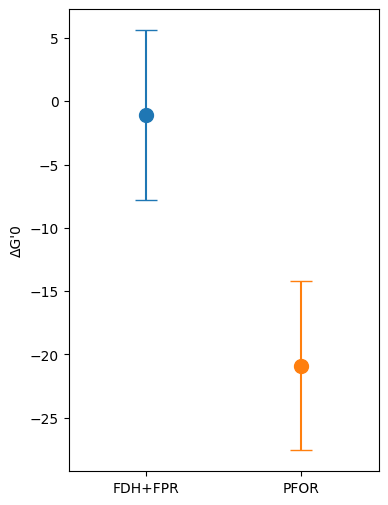

In [ ]:
fig, ax = plt.subplots(figsize=(4,6))

ax.errorbar(0.5, standard_dg_primes[2][1],yerr=standard_dg_primes[2][2],capsize=8,marker='o',ms=10)
ax.errorbar(1, standard_dg_primes[3][1],yerr=standard_dg_primes[3][2],capsize=8,marker='o',ms=10)

ax.set_xlim((0.25,1.25))
ax.set_xticks([0.5,1])
ax.set_xticklabels([standard_dg_primes[2][0],standard_dg_primes[3][0]])
ax.set_ylabel("ΔG'0")
plt.savefig('rxn_dG.eps')
plt.show()

## Then calculate pathway thermodynamics
Anaerobic condition: 98% N2, 2% H2
Henry's law constants:
* H2: 7.8e-4 mol/L/atm
* N2: 6.1e-4 mol/L/atm
* CO2: 3.4e-2 mol/L/atm 

In [9]:
c_h2 = Q_("7.8e-4 mol/L/atm") * 0.02 * Q_("1 atm")
c_h2.to("mM")

<Quantity(0.015600000000000001, 'millimolar')>

In [10]:
c_n2 = Q_("6.1e-4 mol/L/atm") * 0.98 * Q_("1 atm")
c_n2.to("mM")

<Quantity(0.5978000000000001, 'millimolar')>

In [11]:
def MDF(psw):
    print(psw)
    model = ThermodynamicModel.from_sbtab(f"{psw}.tsv", comp_contrib=comp_contrib) 
    print('Net reaction: ', model.net_reaction_formula)

    model.update_standard_dgs()
    mdf_result = model.mdf_analysis()
    mdf = mdf_result.score
    print(f'MDF: {mdf: .2f} kJ/mol')
    display(mdf_result.reaction_df)

    fig, ax = plt.subplots(1, 1, figsize=(4, 4))
    mdf_result.plot_driving_forces(ax)
    ax.grid('on')
    # fig.savefig(f'mdf_result_{psw}.eps')
    plt.show()

    fig, ax = plt.subplots(1, 1, figsize=(6, 6))
    mdf_result.plot_concentrations(ax)
    plt.show()

## Under default conditions

Fdh_Fpr_AOR
Net reaction:  3pg + for = co2 + gap + h2o
MDF: -9.01 kJ/mol


,reaction_id,reaction_formula,flux,original_standard_dg_prime,standard_dg_prime,physiological_dg_prime,optimized_dg_prime,shadow_price
0,FDH,for + nadp = co2 + nadph,1.00 mM/s,-14.41 kJ/mol,-14.00 kJ/mol,-14.00 kJ/mol,-9.64 kJ/mol,0.00000
1,FPR,2 fdxo + nadph = 2 fdxr + nadp,1.00 mM/s,13.32 kJ/mol,14.71 kJ/mol,14.71 kJ/mol,9.01 kJ/mol,0.49726
2,AOR,3pg + 2 fdxr = 2 fdxo + gap + h2o,1.00 mM/s,34.70 kJ/mol,31.83 kJ/mol,31.83 kJ/mol,9.01 kJ/mol,0.50274


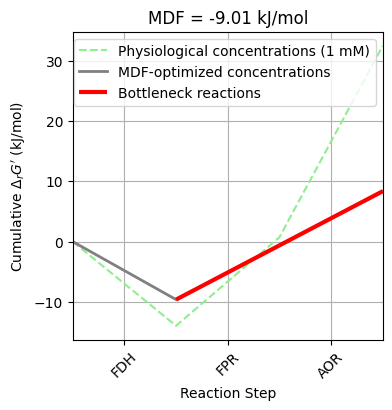

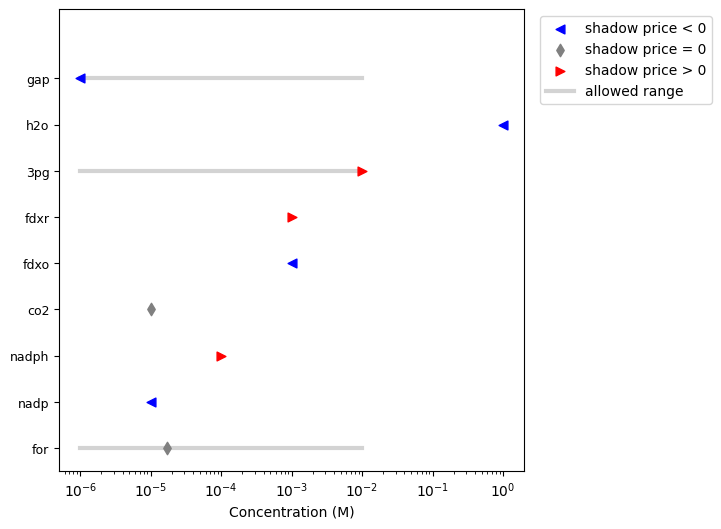

Fdh_Fpr_H2ase
Net reaction:  for = co2 + h2
MDF:  0.61 kJ/mol


,reaction_id,reaction_formula,flux,original_standard_dg_prime,standard_dg_prime,physiological_dg_prime,optimized_dg_prime,shadow_price
0,FDH,for + nadp = co2 + nadph,1.00 mM/s,-14.41 kJ/mol,-14.07 kJ/mol,-14.07 kJ/mol,-10.70 kJ/mol,0.00000
1,FPR,2 fdxo + nadph = 2 fdxr + nadp,1.00 mM/s,13.32 kJ/mol,5.10 kJ/mol,5.10 kJ/mol,-0.61 kJ/mol,0.56183
2,H2ase,2 fdxr = 2 fdxo + h2,1.00 mM/s,25.30 kJ/mol,26.20 kJ/mol,9.08 kJ/mol,-0.61 kJ/mol,0.43817


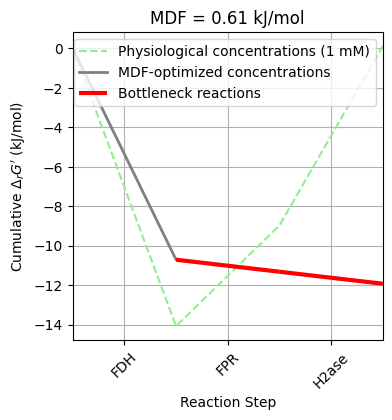

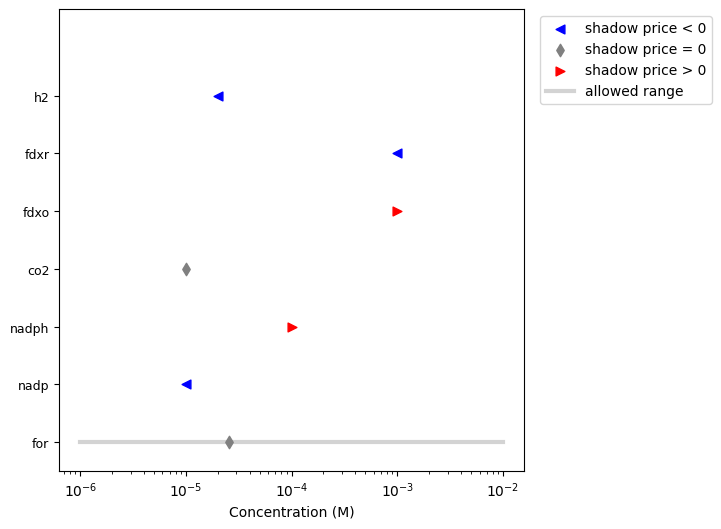

Fdh_Fpr_N2ase
Net reaction:  16 atp + 4 for + 16 h2o + n2 = 16 adp + 4 co2 + h2 + 2 nh3 + 16 pi
MDF:  8.86 kJ/mol


,reaction_id,reaction_formula,flux,original_standard_dg_prime,standard_dg_prime,physiological_dg_prime,optimized_dg_prime,shadow_price
0,FDH,for + nadp = co2 + nadph,4.00 mM/s,-14.41 kJ/mol,-14.25 kJ/mol,-14.25 kJ/mol,-18.52 kJ/mol,0.0
1,FPR,2 fdxo + nadph = 2 fdxr + nadp,4.00 mM/s,13.32 kJ/mol,-3.15 kJ/mol,-3.15 kJ/mol,-8.86 kJ/mol,1.0
2,N2ase,16 atp + 8 fdxr + 16 h2o + n2 = 16 adp + 8 fdx...,1.00 mM/s,-523.07 kJ/mol,-457.65 kJ/mol,-765.71 kJ/mol,-762.73 kJ/mol,0.0


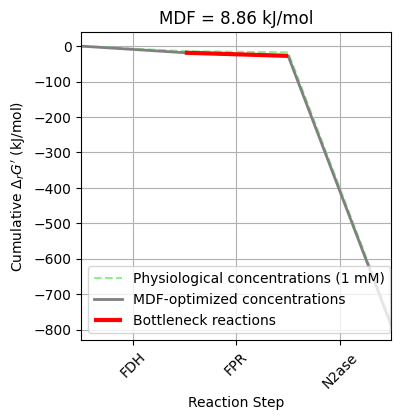

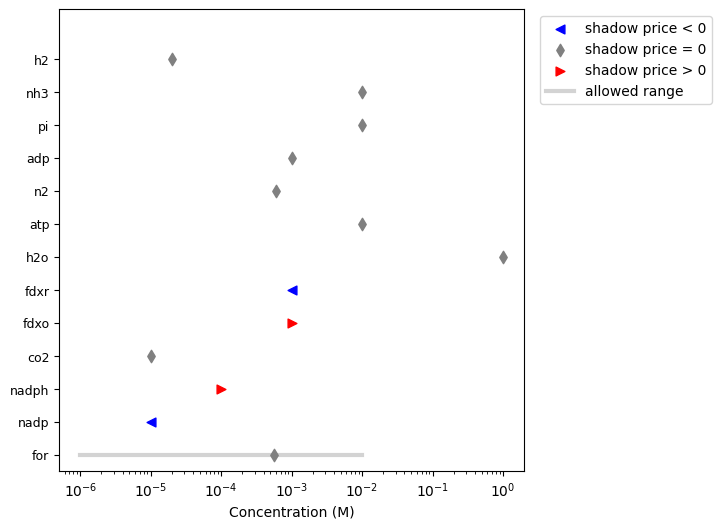

Fdh_Fpr_OGOR
Net reaction:  for + succoa = akg + coa
MDF: -0.59 kJ/mol


,reaction_id,reaction_formula,flux,original_standard_dg_prime,standard_dg_prime,physiological_dg_prime,optimized_dg_prime,shadow_price
0,FDH,for + nadp = co2 + nadph,1.00 mM/s,-14.41 kJ/mol,-8.48 kJ/mol,-8.48 kJ/mol,-6.92 kJ/mol,0.00000
1,FPR,2 fdxo + nadph = 2 fdxr + nadp,1.00 mM/s,13.32 kJ/mol,6.29 kJ/mol,6.29 kJ/mol,0.59 kJ/mol,0.56538
2,OGOR,co2 + 2 fdxr + succoa = akg + coa + 2 fdxo,1.00 mM/s,14.89 kJ/mol,12.00 kJ/mol,12.00 kJ/mol,0.59 kJ/mol,0.43462


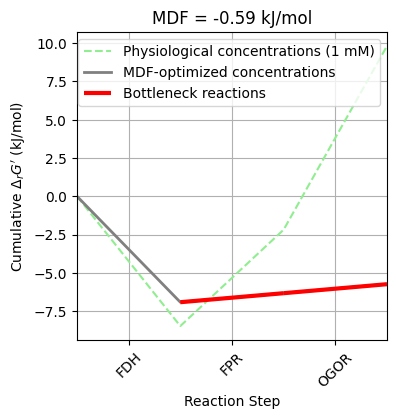

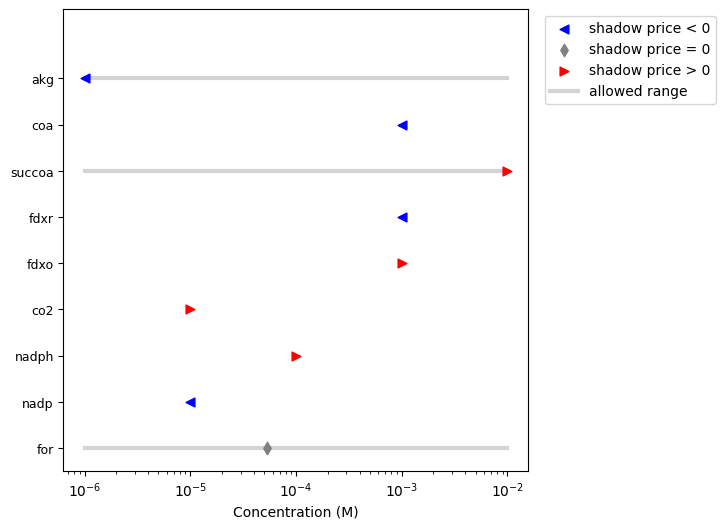

PFOR_AOR
Net reaction:  3pg + coa + pyr = accoa + co2 + gap + h2o
MDF:  2.56 kJ/mol


,reaction_id,reaction_formula,flux,original_standard_dg_prime,standard_dg_prime,physiological_dg_prime,optimized_dg_prime,shadow_price
0,PFOR,coa + 2 fdxo + pyr = accoa + co2 + 2 fdxr,1.00 mM/s,-20.90 kJ/mol,-6.68 kJ/mol,-6.68 kJ/mol,-18.69 kJ/mol,0.0
1,AOR,3pg + 2 fdxr = 2 fdxo + gap + h2o,1.00 mM/s,34.70 kJ/mol,20.26 kJ/mol,20.26 kJ/mol,-2.56 kJ/mol,1.0


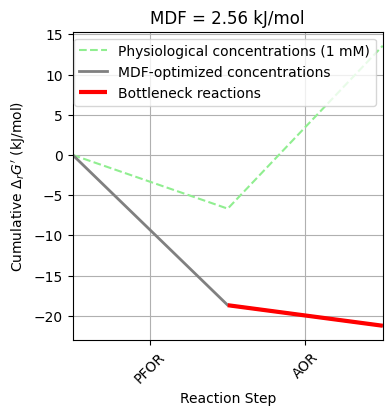

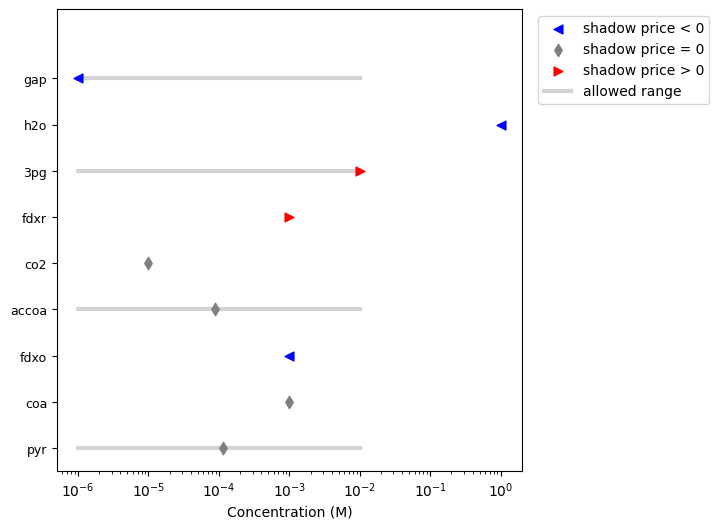

PFOR_H2ase
Net reaction:  coa + pyr = accoa + co2 + h2
MDF:  17.55 kJ/mol


,reaction_id,reaction_formula,flux,original_standard_dg_prime,standard_dg_prime,physiological_dg_prime,optimized_dg_prime,shadow_price
0,PFOR,coa + 2 fdxo + pyr = accoa + co2 + 2 fdxr,1.00 mM/s,-20.90 kJ/mol,-8.06 kJ/mol,-8.06 kJ/mol,-19.78 kJ/mol,0.0
1,H2ase,2 fdxr = 2 fdxo + h2,1.00 mM/s,25.30 kJ/mol,9.25 kJ/mol,-7.86 kJ/mol,-17.55 kJ/mol,1.0


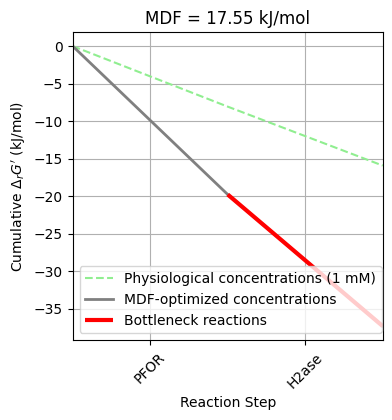

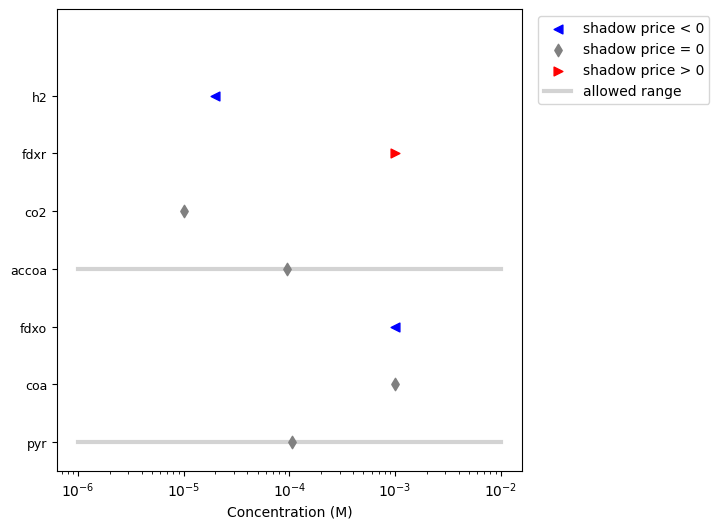

PFOR_N2ase
Net reaction:  16 atp + 4 coa + 16 h2o + n2 + 4 pyr = 4 accoa + 16 adp + 4 co2 + h2 + 2 nh3 + 16 pi
MDF:  71.46 kJ/mol


,reaction_id,reaction_formula,flux,original_standard_dg_prime,standard_dg_prime,physiological_dg_prime,optimized_dg_prime,shadow_price
0,PFOR,coa + 2 fdxo + pyr = accoa + co2 + 2 fdxr,4.00 mM/s,-20.90 kJ/mol,-37.23 kJ/mol,-37.23 kJ/mol,-71.46 kJ/mol,1.0
1,N2ase,16 atp + 8 fdxr + 16 h2o + n2 = 16 adp + 8 fdx...,1.00 mM/s,-523.07 kJ/mol,-471.99 kJ/mol,-780.06 kJ/mol,-777.08 kJ/mol,0.0


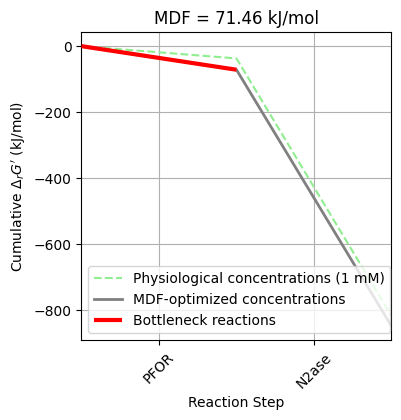

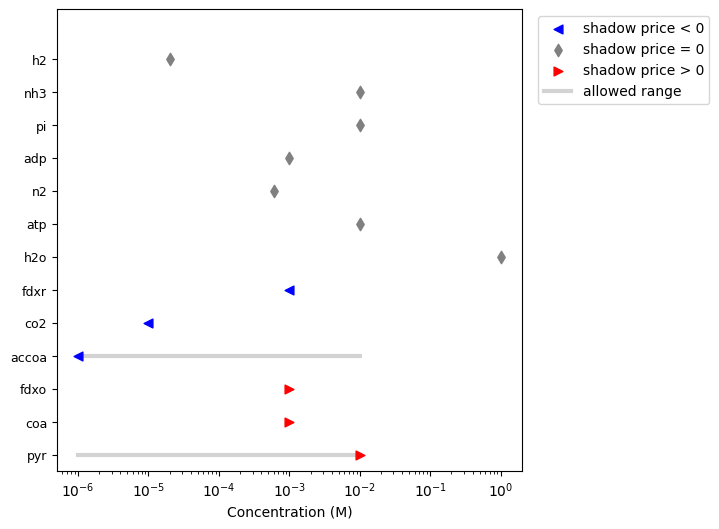

PFOR_OGOR
Net reaction:  pyr + succoa = accoa + akg
MDF:  13.68 kJ/mol


,reaction_id,reaction_formula,flux,original_standard_dg_prime,standard_dg_prime,physiological_dg_prime,optimized_dg_prime,shadow_price
0,PFOR,coa + 2 fdxo + pyr = accoa + co2 + 2 fdxr,1.00 mM/s,-20.90 kJ/mol,-5.72 kJ/mol,-5.72 kJ/mol,-20.11 kJ/mol,0.0
1,OGOR,co2 + 2 fdxr + succoa = akg + coa + 2 fdxo,1.00 mM/s,14.89 kJ/mol,-2.27 kJ/mol,-2.27 kJ/mol,-13.68 kJ/mol,1.0


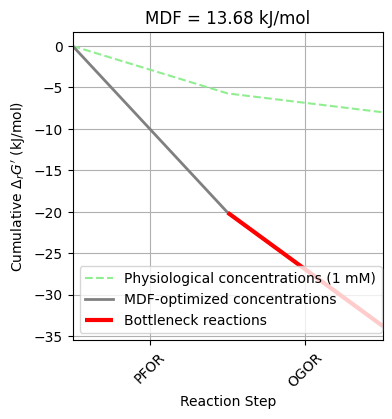

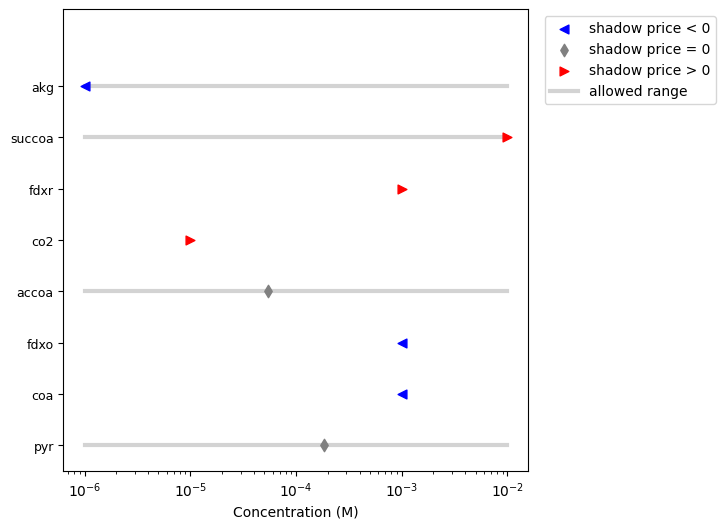

In [12]:
psws = ['Fdh_Fpr_AOR', 'Fdh_Fpr_H2ase', 'Fdh_Fpr_N2ase', 'Fdh_Fpr_OGOR', 
        'PFOR_AOR', 'PFOR_H2ase','PFOR_N2ase','PFOR_OGOR']

for psw in psws: 
    MDF(psw)

In [13]:
def loadModel(psw):
    print(psw)
    model = ThermodynamicModel.from_sbtab(f"{psw}.tsv", comp_contrib=comp_contrib) 
    print('Net reaction: ', model.net_reaction_formula)
    return model

def MDF_updated_bounds(model, cmp1, b1, cmp2,b2):
    model.set_bounds(cid=cmp1, ub=Q_(b1, ureg.mM),lb=Q_(b1, ureg.mM))
    model.set_bounds(cid=cmp2, ub=Q_(b2, ureg.mM),lb=Q_(b2, ureg.mM))
    model.update_standard_dgs()
    mdf_result = model.mdf_analysis()
    return mdf_result.score

## FdxR-FdxO ratio between 0.1 to 10

In [ ]:
mdf_results = pd.DataFrame()

ratios=np.geomspace(0.1, 10, num=51)
b1 = 1

for psw in psws:
    model = loadModel(psw)
    for i, ratio in enumerate(ratios):
        b2 = b1/ratio

        mdf_results.loc[i,"fdxr-fdxo-ratio"]=ratio
        mdf_results.loc[i,psw]=MDF_updated_bounds(model, 'fdxr',b1, 'fdxo',b2)

mdf_results.to_excel('PFOR_MDF_at_fdxR-fdxO.xlsx')

Fdh_Fpr_AOR
Net reaction:  3pg + for = co2 + gap + h2o
Fdh_Fpr_H2ase
Net reaction:  for = co2 + h2
Fdh_Fpr_N2ase
Net reaction:  16 atp + 4 for + 16 h2o + n2 = 16 adp + 4 co2 + h2 + 2 nh3 + 16 pi
Fdh_Fpr_OGOR
Net reaction:  for + succoa = akg + coa
PFOR_AOR
Net reaction:  3pg + coa + pyr = accoa + co2 + gap + h2o
PFOR_H2ase
Net reaction:  coa + pyr = accoa + co2 + h2
PFOR_N2ase
Net reaction:  16 atp + 4 coa + 16 h2o + n2 + 4 pyr = 4 accoa + 16 adp + 4 co2 + h2 + 2 nh3 + 16 pi
PFOR_OGOR
Net reaction:  pyr + succoa = accoa + akg


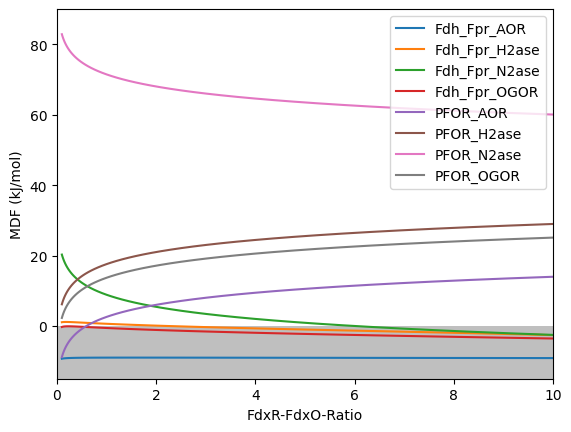

In [ ]:
fig, ax = plt.subplots()
mdf_results.plot(x='fdxr-fdxo-ratio', ax=ax)
ax.fill_between(x=[0,10],y1=-15,facecolor="grey",alpha=0.5)
plt.setp(
    ax, ylabel='MDF (kJ/mol)', ylim=(-15, 90),
    xlim=(0, 10), xlabel='FdxR-FdxO-Ratio'
)
plt.savefig('PFOR-mdf_linearX.eps')
plt.show()

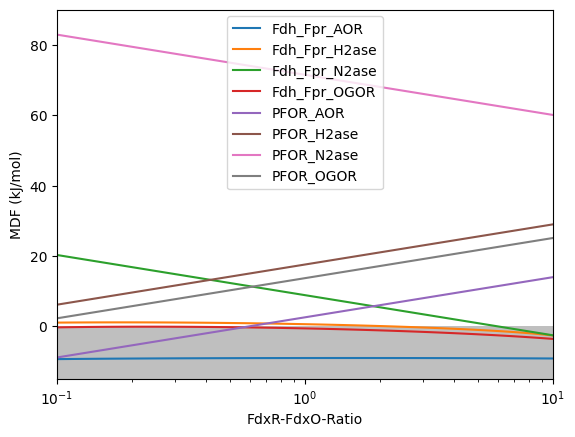

In [ ]:
ax.set_xlim((0.1,10))
ax.set_xscale("log")
fig.savefig('PFOR-mdf_logX.eps')
display(fig)

PFOR for NADPH-Aux strain

Net reaction:  coa + nadp + pyr = accoa + co2 + nadph
MDF:  22.04 kJ/mol


,reaction_id,reaction_formula,flux,original_standard_dg_prime,standard_dg_prime,physiological_dg_prime,optimized_dg_prime,shadow_price
0,PFOR,coa + 2 fdxo + pyr = accoa + co2 + 2 fdxr,1.00 mM/s,-20.90 kJ/mol,-6.62 kJ/mol,-6.62 kJ/mol,-23.58 kJ/mol,0.0
1,FNR,2 fdxr + nadp = 2 fdxo + nadph,1.00 mM/s,-13.32 kJ/mol,-27.75 kJ/mol,-27.75 kJ/mol,-22.04 kJ/mol,1.0


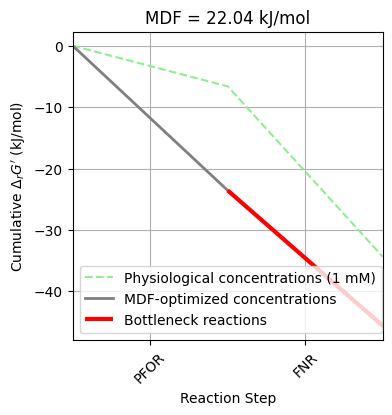

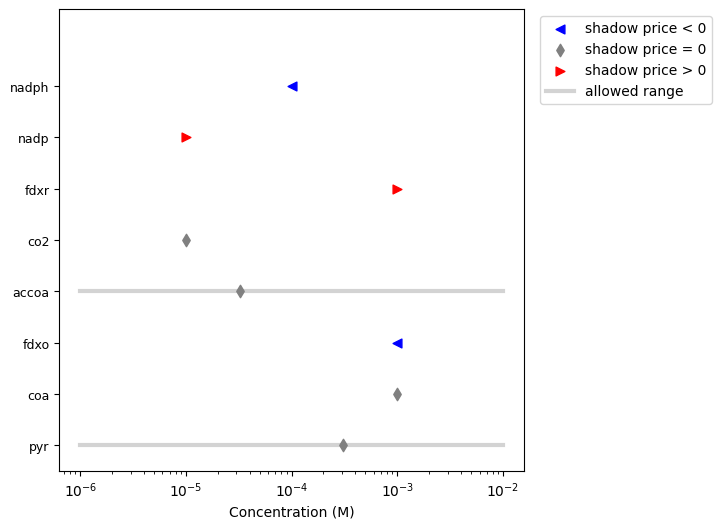

In [17]:
model = ThermodynamicModel.from_sbtab("PFOR_FNR.tsv", comp_contrib=comp_contrib) 
print('Net reaction: ', model.net_reaction_formula)

model.update_standard_dgs()
mdf_result = model.mdf_analysis()
mdf = mdf_result.score
print(f'MDF: {mdf: .2f} kJ/mol')
display(mdf_result.reaction_df)

fig, ax = plt.subplots(1, 1, figsize=(4, 4))
mdf_result.plot_driving_forces(ax)
ax.grid('on')
fig.savefig(f'mdf_result_PFOR_FNR.eps')
plt.show()

fig, ax = plt.subplots(1, 1, figsize=(6, 6))
mdf_result.plot_concentrations(ax)
plt.show()